# 9. Outliers and the rejection of data

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 4 and 5

**Reading:** Taylor, ch. 6 · Fornasini, ch. 9.3 · Huber and Ronchetti,
*Robust Statistics*, ch. 1

Sooner or later every experimenter meets a reading that does not fit: one
value far from the others with no obvious cause. Is it a mistake to be
discarded, a rare but legitimate fluctuation, or the most interesting
measurement of the day? Statistics cannot answer the question, but it can
say how unusual the reading is, what discarding it does to the result, and
how to compute results that are not at the mercy of a single bad value.

This chapter

1. presents Chauvenet's criterion, the classic rule for rejecting data;
2. tests it by simulation, on clean data and on data with genuine blunders;
3. introduces robust estimators (median, trimmed mean, Huber's M-estimator)
   that limit the influence of outliers without discarding anything;
4. ends with a practical policy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(109)

## 9.1 Chauvenet's criterion

From $N$ readings compute $\bar x$ and $s$. For the suspect reading
$x_\text{sus}$ compute $t = |x_\text{sus} - \bar x|/s$ and the probability
$P(|z| > t)$ that a normal reading deviates at least this much. The
expected number of such readings among $N$ is $n = N\,P(|z| > t)$.
**Chauvenet's criterion** rejects the suspect reading if $n < \tfrac12$
(Taylor, ch. 6). The threshold $t_\text{C}$ therefore grows with $N$:

In [2]:
def chauvenet_threshold(N):
    return stats.norm.isf(0.25 / N)          # N * 2 * P(z > t) = 1/2

for N in (5, 10, 20, 50, 100, 1000):
    print(f"N = {N:5d}: reject beyond {chauvenet_threshold(N):.2f} standard deviations")

x10 = np.array([46, 48, 44, 38, 45, 47, 58, 44, 45, 43], dtype=float)     # Taylor's ten lengths (mm)
m, s = x10.mean(), x10.std(ddof=1)
t = abs(58 - m) / s
print(f"\nten lengths: mean {m:.1f}, s = {s:.2f}; the reading 58 lies {t:.2f} s from the mean, "
      f"n = {10 * 2 * stats.norm.sf(t):.2f} -> {'reject' if 10 * 2 * stats.norm.sf(t) < 0.5 else 'keep'}")

N =     5: reject beyond 1.64 standard deviations
N =    10: reject beyond 1.96 standard deviations
N =    20: reject beyond 2.24 standard deviations
N =    50: reject beyond 2.58 standard deviations
N =   100: reject beyond 2.81 standard deviations
N =  1000: reject beyond 3.48 standard deviations

ten lengths: mean 45.8, s = 5.07; the reading 58 lies 2.40 s from the mean, n = 0.16 -> reject


Taylor himself is careful to call the criterion a compromise and to note
that many scientists are uncomfortable with it. Two features deserve a
test. First, the threshold is chosen so that on average half a legitimate
reading per data set would be rejected; how often does the criterion
throw out good data? Second, $\bar x$ and $s$ are computed *with* the suspect
reading included, which pulls them towards it. What do these choices do to
the final result?

## 9.2 Chauvenet's criterion on clean data

Apply the criterion to many sets of $N$ perfectly normal readings, once
(to the most deviant reading), as recommended, and also repeatedly until
nothing more is rejected, which is a common misuse.

In [3]:
def chauvenet_once(x):
    m, s = x.mean(), x.std(ddof=1)
    i = np.argmax(np.abs(x - m))
    if x.size * 2 * stats.norm.sf(abs(x[i] - m) / s) < 0.5:
        return np.delete(x, i)
    return x

def chauvenet_repeated(x):
    while True:
        y = chauvenet_once(x)
        if y.size == x.size or y.size < 3:
            return y
        x = y

n_sets = 20_000
rows = []
for N in (5, 10, 20, 50):
    X = rng.normal(0, 1, (n_sets, N))
    once = [chauvenet_once(x) for x in X]
    rep = [chauvenet_repeated(x) for x in X]
    frac_once = np.mean([y.size < N for y in once])
    lost_rep = np.mean([N - y.size for y in rep])
    # coverage of mean +/- s/sqrt(N) computed from the kept readings
    cov_all = np.mean(np.abs(X.mean(axis=1)) < X.std(axis=1, ddof=1) / np.sqrt(N))
    cov_once = np.mean([abs(y.mean()) < y.std(ddof=1) / np.sqrt(y.size) for y in once])
    cov_rep = np.mean([abs(y.mean()) < y.std(ddof=1) / np.sqrt(y.size) for y in rep])
    rows.append((N, frac_once, lost_rep, cov_all, cov_once, cov_rep))
print("  N   sets losing a good reading (once)   good readings lost (repeated)   coverage: all   once   repeated")
for N, f1, lr, ca, c1, cr in rows:
    print(f"{N:3d}               {f1:.3f}                          {lr:.2f}                   {ca:.3f}   {c1:.3f}   {cr:.3f}")

  N   sets losing a good reading (once)   good readings lost (repeated)   coverage: all   once   repeated
  5               0.132                          0.13                   0.625   0.567   0.567
 10               0.279                          0.38                   0.656   0.586   0.575
 20               0.326                          0.46                   0.673   0.625   0.610
 50               0.353                          0.49                   0.677   0.650   0.642


Applied once, the criterion discards a perfectly good reading in a
substantial fraction of data sets. Applied repeatedly, it keeps going:
after the first rejection $s$ shrinks, the next most extreme reading now
looks deviant, and it too is removed. The damage to the result is less
visible but more important: by removing the readings that make the scatter
look large, the criterion makes $s$ too small, and the interval
$\bar x \pm s/\sqrt N$ covers the true value less often than it claims.

## 9.3 Data with real blunders

Rejection rules exist for data that *do* contain mistakes: a misread scale,
a transcription error, a moment of contact with the apparatus. Model this
by replacing each reading, with probability $\varepsilon$, by a blunder
drawn from a much wider distribution (standard deviation 10 instead of 1).
Compare five ways of estimating the centre:

* the mean of all readings;
* the mean after a single application of Chauvenet's criterion;
* the **median**;
* the **trimmed mean**, discarding the lowest and highest 10 %;
* **Huber's M-estimator**, `ep.huber_location`, a weighted mean in which
  readings more than 1.345 robust standard deviations from the centre are
  down-weighted in proportion to their distance (the robust standard
  deviation is the median absolute deviation times 1.4826, `ep.mad`).

The measure of quality is the root-mean-square error over many simulated
data sets of 20 readings.

In [4]:
def trimmed_mean(x, frac=0.1):
    return stats.trim_mean(x, frac)

estimators = {
    "mean": np.mean,
    "Chauvenet, then mean": lambda x: chauvenet_once(x).mean(),
    "median": np.median,
    "10 % trimmed mean": trimmed_mean,
    "Huber M-estimate": ep.huber_location,
}
eps_values = np.array([0.0, 0.02, 0.05, 0.10, 0.20])
N, n_sets = 20, 5000
rmse = {k: [] for k in estimators}
for eps in eps_values:
    X = rng.normal(0, 1, (n_sets, N))
    bad = rng.random((n_sets, N)) < eps
    X[bad] = rng.normal(0, 10, bad.sum())
    for name, f in estimators.items():
        est = np.array([f(x) for x in X])
        rmse[name].append(np.sqrt(np.mean(est**2)))
print("contamination:       " + "  ".join(f"{e:5.0%}" for e in eps_values))
for name in estimators:
    print(f"{name:21s}" + "  ".join(f"{v:5.3f}" for v in rmse[name]))
print(f"\nideal for clean data: 1/sqrt(20) = {1 / np.sqrt(20):.3f}")

contamination:          0%     2%     5%    10%    20%
mean                 0.223  0.389  0.543  0.748  1.023
Chauvenet, then mean 0.235  0.255  0.316  0.462  0.771
median               0.272  0.276  0.284  0.300  0.340
10 % trimmed mean    0.229  0.238  0.254  0.315  0.536
Huber M-estimate     0.230  0.239  0.248  0.276  0.362

ideal for clean data: 1/sqrt(20) = 0.224


Three conclusions follow.

* On clean data the mean is best, as it must be (it is the maximum-likelihood
  estimate, Section 7.3). The median pays its price of about 20 % in
  uncertainty; the Huber estimate and the trimmed mean pay only a few
  per cent.
* With even a few per cent of blunders the mean deteriorates quickly, and a
  single pass of Chauvenet's criterion repairs only part of the damage,
  because it removes at most one reading and its threshold is computed from a
  standard deviation that the blunders themselves have inflated.
* The robust estimators lose very little on clean data and stay close to the
  ideal as contamination grows. The Huber estimate is the best compromise
  across the whole range.

Robust estimators need uncertainties too. The **bootstrap** (Efron 1979;
`ep.bootstrap`) provides one without any formula: draw many new samples of
the same size from the data themselves, with replacement, compute the
estimator for each, and take the standard deviation of the results as its
standard uncertainty. (The jackknife of Section 17.5 is a close relative.) In the example below,
two of twenty readings are blunders, both on the high side.

In [5]:
x = rng.normal(10.0, 0.5, 20)
x[[3, 11]] = [14.2, 12.9]                    # two blunders, both high
for name, f in (("mean", np.mean), ("median", np.median), ("Huber", ep.huber_location)):
    est, se, _ = ep.bootstrap(x, f, n_boot=4000, rng=rng)
    print(f"{name:7s}: {ep.format_result(est, se)}")
print(f"true value 10.0; standard error of the mean of 20 clean readings: {0.5 / np.sqrt(20):.2f}")

mean   : 10.30 ± 0.26
median : 9.97 ± 0.19


Huber  : 10.06 ± 0.17
true value 10.0; standard error of the mean of 20 clean readings: 0.11


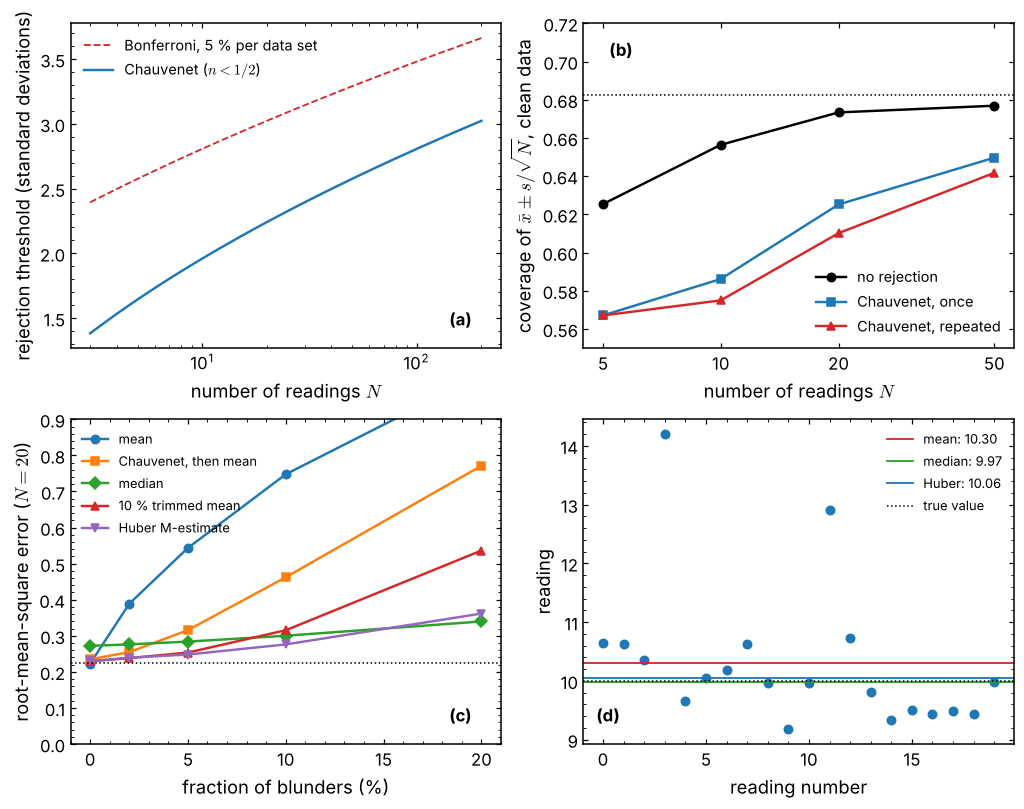

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
NN = np.arange(3, 201)
ax.plot(NN, chauvenet_threshold(NN), "C0")
ax.plot(NN, stats.norm.isf(0.025 / NN), "C3--", lw=1.2, label="Bonferroni, 5 % per data set")
ax.set_xscale("log"); ax.set_xlabel("number of readings $N$")
ax.set_ylabel("rejection threshold (standard deviations)")
ax.plot([], [], "C0", label="Chauvenet ($n < 1/2$)")
ax.legend(loc="upper left"); ep.panel_label(ax, "(a)", x=0.88, y=0.12)

ax = axes[0, 1]
Ns = [r[0] for r in rows]
ax.plot(Ns, [r[3] for r in rows], "o-", color="k", label="no rejection")
ax.plot(Ns, [r[4] for r in rows], "s-", color="C0", label="Chauvenet, once")
ax.plot(Ns, [r[5] for r in rows], "^-", color="C3", label="Chauvenet, repeated")
ax.axhline(0.6827, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("number of readings $N$")
ax.set_ylabel(r"coverage of $\bar x \pm s/\sqrt{N}$, clean data")
ax.set_xticks([5, 10, 20, 50]); ax.set_xticklabels(["5", "10", "20", "50"]); ax.minorticks_off()
ax.set_ylim(0.55, 0.72); ax.legend(loc="lower right"); ep.panel_label(ax, "(b)", x=0.06)

ax = axes[1, 0]
for (name, vals), mk in zip(rmse.items(), "osD^v"):
    ax.plot(100 * eps_values, vals, marker=mk, label=name)
ax.axhline(1 / np.sqrt(20), color="k", ls=":", lw=1)
ax.set_xlabel("fraction of blunders (%)"); ax.set_ylabel("root-mean-square error ($N = 20$)")
ax.set_ylim(0, 0.9); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.88, y=0.12)

ax = axes[1, 1]
ax.plot(np.arange(x.size), x, "o", color="C0")
for val, c, lab in ((x.mean(), "C3", "mean"), (np.median(x), "C2", "median"), (ep.huber_location(x), "C0", "Huber")):
    ax.axhline(val, color=c, lw=1.2, label=f"{lab}: {val:.2f}")
ax.axhline(10.0, color="k", ls=":", lw=1, label="true value")
ax.set_xlabel("reading number"); ax.set_ylabel("reading")
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)", y=0.12)
plt.show()

**(a)** Chauvenet's threshold against the number of readings, compared
with a threshold that limits the chance of rejecting any good reading in a
data set to 5 %. **(b)** Coverage of the usual interval after applying the
criterion to clean data. **(c)** Accuracy of five estimators of the centre
as blunders are added. **(d)** A data set with two blunders and three
estimates of its centre.

## 9.4 A policy for suspect data

1. **Investigate first.** Check the notebook, the instrument, the
   conditions. A reading with a known cause (a dropped weight, a
   misrecorded digit) is removed for that cause, whatever its size.
2. **Never reject silently.** Report every rejected value, the reason, and
   the result with and without it. A reader who disagrees can then
   recompute.
3. **Prefer robust estimates to rejection rules** when blunders are
   expected but cannot be identified individually. They use all the data and
   degrade gracefully.
4. **Be suspicious of your own suspicion.** Readings that disagree with the
   expected answer are scrutinised more closely than readings that agree,
   which biases the result towards expectation. Decide the rule before
   seeing the data.
5. **Remember the history of science.** Some outliers are discoveries.

Formal tests for a single outlier with a stated false-alarm probability,
such as Grubbs' test, are preferable to Chauvenet's fixed $n < \tfrac12$ when a
test is wanted at all.

## Summary

* Chauvenet's criterion rejects a reading if fewer than half a reading that
  deviant would be expected among $N$; the threshold rises with $N$.
* On clean data it removes good readings in a sizeable fraction of data sets
  and makes the quoted uncertainty too small, especially if applied
  repeatedly.
* Robust estimators (median, trimmed mean, Huber) resist blunders without
  discarding data; Huber's estimator loses only a few per cent on clean data.
* Investigate, document, and report with and without suspect values.

## References

* P. J. Huber and E. M. Ronchetti, *Robust Statistics*, 2nd ed. (Wiley,
  2009).
* B. Efron, "Bootstrap methods: another look at the jackknife", *Ann.
  Statist.* **7**, 1 (1979).
* B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*
  (Chapman & Hall, 1993).
* F. E. Grubbs, "Procedures for detecting outlying observations in
  samples", *Technometrics* **11**, 1 (1969).

## Exercises

1. Apply Chauvenet's criterion to the ten lengths of Section 9.1 a second
   time, after removing the value 58. What happens, and why does Taylor
   advise against doing this?
2. Show that Chauvenet's threshold for $N$ readings is the
   $1 - 1/(4N)$ quantile of the standard normal distribution.
3. Repeat the simulation of Section 9.3 with blunders that are all positive
   (for example a reading error that always adds 5). Which estimators are
   now biased, and by how much?
4. For normal data, the efficiency of the median relative to the mean tends
   to $2/\pi$. Verify by simulation for $N = 101$.
5. Find the Huber constant $c$ that gives 90 % efficiency on normal data,
   and compare its performance with $c = 1.345$ at 10 % contamination.

---

**Previous:** [8. Hypothesis tests and goodness of fit](08_hypothesis_tests.ipynb) &nbsp;·&nbsp; **Next:** [10. Monte Carlo methods](10_monte_carlo_methods.ipynb)